# Alzheimer’s MRI Classification — Baseline CNN Research Notebook

**Purpose:** prepare the MRI image branch from dataset audit and preprocessing through baseline CNN training, validation, and held-out test evaluation. This notebook is designed so another group member can add and compare further models in the clearly marked model-comparison section.

**Scope:** MRI images only. The clinical CSV branch is handled separately by other team members.

## Important research note
The previous pilot trained the custom CNN for **one epoch** and reported training accuracy **52.48%** and validation accuracy **50.38%**. The test set was not evaluated in that pilot.

An earlier filename-based audit flagged possible source/augmentation groups appearing across splits. Because filenames such as `26.jpg` are reused in different class folders, that filename normalization is not proof of leakage. Treat the current split as **not yet verified for patient/source independence**. Test metrics produced here are therefore provisional until the split has been reviewed. Do not report them as reliable generalization performance without resolving this issue.

**This notebook does not alter or move original images or the saved split manifest.**

## 1. Configuration and paths

The previous MRI workflow used:
- Images: `D:\project\combined_images`
- Saved split manifest: `D:\project\Outputs\mri_split_manifest.csv`

If these folders have moved, update the paths below. Keep the manifest created previously so the split is not silently regenerated.

## Recovery and rerun safety

If training is interrupted, this version reads completed epochs from `Outputs/mri_baseline_cnn/training_history.csv` and restores the best saved validation checkpoint if available. Plotting and test evaluation reload saved files, so they can run after a kernel restart.

The optimizer state is not stored in the checkpoint; a resumed epoch therefore uses a freshly initialized optimizer. This is a practical recovery path, not an exact continuation of the interrupted optimizer state.

In [1]:
from pathlib import Path
import os
import sys
import json
import random
import time
import copy
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

# ---- Project paths from the existing MRI workflow ----
PROJECT_DIR = Path(r"D:\project")
IMAGE_DIR = PROJECT_DIR / "combined_images"
OUTPUT_DIR = PROJECT_DIR / "Outputs"
MANIFEST_PATH = OUTPUT_DIR / "mri_split_manifest.csv"
MODEL_OUTPUT_DIR = OUTPUT_DIR / "mri_baseline_cnn"
MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- Reproducibility ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ---- Training configuration ----
IMAGE_SIZE = 160
BATCH_SIZE = 32
NUM_EPOCHS = 3          # CPU pilot took ~22 minutes per epoch; adjust if needed.
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
DROPOUT_RATE = 0.4
EARLY_STOPPING_PATIENCE = 2
NUM_WORKERS = 0         # Safe default for Windows/Jupyter.

CLASS_NAMES = [
    "MildDemented",
    "ModerateDemented",
    "NonDemented",
    "VeryMildDemented"
]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)
print("Image directory exists:", IMAGE_DIR.is_dir())
print("Manifest exists:", MANIFEST_PATH.is_file())

assert IMAGE_DIR.is_dir(), f"Image folder not found: {IMAGE_DIR}"
assert MANIFEST_PATH.is_file(), f"Split manifest not found: {MANIFEST_PATH}"

Python: 3.13.9
Platform: Windows-11-10.0.26200-SP0
PyTorch: 2.15.0+cpu
Torchvision: 0.29.2+cpu
Device: cpu
Image directory exists: True
Manifest exists: True


## 2. Load and audit the saved manifest

The manifest defines the existing `train`, `validation`, and `test` assignments. This cell checks schema, labels, split names, missing paths, repeated paths, and class counts. It does not create a new split.

In [2]:
manifest = pd.read_csv(MANIFEST_PATH)

required_columns = {"image_path", "label", "split"}
missing_columns = required_columns - set(manifest.columns)
assert not missing_columns, f"Manifest is missing columns: {missing_columns}"

manifest = manifest[["image_path", "label", "split"]].copy()
manifest["image_path"] = manifest["image_path"].astype(str)
manifest["label"] = manifest["label"].astype(str)
manifest["split"] = manifest["split"].astype(str).str.lower().str.strip()

print("Manifest shape:", manifest.shape)
print("\nRows by split:")
print(manifest["split"].value_counts())

print("\nClass distribution:")
print(manifest["label"].value_counts().reindex(CLASS_NAMES, fill_value=0))

print("\nClass distribution by split:")
display(pd.crosstab(manifest["label"], manifest["split"]).reindex(CLASS_NAMES, fill_value=0))

unknown_labels = sorted(set(manifest["label"]) - set(CLASS_NAMES))
unknown_splits = sorted(set(manifest["split"]) - {"train", "validation", "test"})
assert not unknown_labels, f"Unexpected labels found: {unknown_labels}"
assert not unknown_splits, f"Unexpected split names found: {unknown_splits}"

missing_path_mask = ~manifest["image_path"].map(lambda p: Path(p).is_file())
print("\nMissing image paths:", int(missing_path_mask.sum()))
print("Repeated manifest paths:", int(manifest["image_path"].duplicated().sum()))

assert not missing_path_mask.any(), (
    "Some paths in the manifest do not exist. Inspect the paths before training."
)
assert not manifest["image_path"].duplicated().any(), (
    "Repeated image paths exist in the manifest; resolve before training."
)

split_counts = manifest["split"].value_counts().to_dict()
print("\nAudit passed: manifest paths exist and each path occurs once.")

Manifest shape: (44000, 3)

Rows by split:
split
train         30800
validation     6600
test           6600
Name: count, dtype: int64

Class distribution:
label
MildDemented        10000
ModerateDemented    10000
NonDemented         12800
VeryMildDemented    11200
Name: count, dtype: int64

Class distribution by split:


split,test,train,validation
label,,,
MildDemented,1500,7000,1500
ModerateDemented,1500,7000,1500
NonDemented,1920,8960,1920
VeryMildDemented,1680,7840,1680



Missing image paths: 0
Repeated manifest paths: 0

Audit passed: manifest paths exist and each path occurs once.


## 3. Image integrity and source-split caution

The earlier full readability audit found 44,000 readable images and no corrupt files. The cell below can be rerun if the dataset has changed. It is a full scan and may take a few minutes.

**Important:** unique file paths do not prove that images are independent. Augmented copies or images from the same patient/source may still cross splits. Filename-based grouping is only a clue and can be wrong when filenames are reused. Confirm source/patient grouping with the dataset’s original metadata or a defensible duplicate-detection method before making strong test-performance claims.

In [3]:
RUN_FULL_IMAGE_INTEGRITY_SCAN = False  # Set True to recheck all 44,000 images.

if RUN_FULL_IMAGE_INTEGRITY_SCAN:
    bad_files = []
    mode_counts = {}
    size_counts = {}

    for i, image_path in enumerate(manifest["image_path"], start=1):
        try:
            with Image.open(image_path) as im:
                im.verify()
            with Image.open(image_path) as im:
                mode_counts[im.mode] = mode_counts.get(im.mode, 0) + 1
                size_counts[im.size] = size_counts.get(im.size, 0) + 1
        except Exception as exc:
            bad_files.append({"image_path": image_path, "error": str(exc)})

        if i % 5000 == 0:
            print(f"Checked {i:,}/{len(manifest):,}")

    print("Unreadable images:", len(bad_files))
    print("Image modes:", mode_counts)
    print("Most common dimensions:",
          sorted(size_counts.items(), key=lambda item: item[1], reverse=True)[:10])

    if bad_files:
        bad_path = OUTPUT_DIR / "unreadable_mri_images.csv"
        pd.DataFrame(bad_files).to_csv(bad_path, index=False)
        print("Unreadable image report saved to:", bad_path)
else:
    print("Full scan skipped. Using the previous audit result: 44,000 readable images, 0 unreadable.")

Full scan skipped. Using the previous audit result: 44,000 readable images, 0 unreadable.


## 4. Preprocessing and data loaders

All images are converted to grayscale, resized to `160 × 160`, converted to tensors, and normalized from `[0, 1]` to approximately `[-1, 1]`. Only the training loader is shuffled. Validation and test loaders preserve their order.

In [4]:
image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

class MRIDataset(Dataset):
    def __init__(self, frame, transform=None):
        self.frame = frame.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row["image_path"]) as im:
            image = im.convert("L")
            if self.transform is not None:
                image = self.transform(image)

        label = CLASS_TO_IDX[row["label"]]
        return image, label

train_df = manifest.loc[manifest["split"] == "train"].copy()
val_df = manifest.loc[manifest["split"] == "validation"].copy()
test_df = manifest.loc[manifest["split"] == "test"].copy()

assert len(train_df) and len(val_df) and len(test_df), (
    "Train, validation, and test splits must all contain images."
)

train_dataset = MRIDataset(train_df, image_transform)
val_dataset = MRIDataset(val_df, image_transform)
test_dataset = MRIDataset(test_df, image_transform)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda")
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda")
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda")
)

sample_images, sample_labels = next(iter(train_loader))
print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Batch image shape:", tuple(sample_images.shape))
print("Batch label shape:", tuple(sample_labels.shape))
print("Normalized pixel range in sample:",
      float(sample_images.min()), "to", float(sample_images.max()))
print("Class mapping:", CLASS_TO_IDX)

assert tuple(sample_images.shape[1:]) == (1, IMAGE_SIZE, IMAGE_SIZE)

Train images: 30800
Validation images: 6600
Test images: 6600
Batch image shape: (32, 1, 160, 160)
Batch label shape: (32,)
Normalized pixel range in sample: -1.0 to 1.0
Class mapping: {'MildDemented': 0, 'ModerateDemented': 1, 'NonDemented': 2, 'VeryMildDemented': 3}


## 5. Baseline model — custom CNN

This is the custom CNN used in the previous one-epoch pilot (not ResNet18). It has four convolutional stages and a four-class output. The first three stages use max pooling; the last stage uses adaptive average pooling. Dropout is applied before the final linear layer.

In [5]:
class AlzheimerCNN(nn.Module):
    def __init__(self, num_classes=4, dropout_rate=0.4):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout_rate),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = AlzheimerCNN(
    num_classes=len(CLASS_NAMES),
    dropout_rate=DROPOUT_RATE
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

trainable_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

model.eval()
with torch.no_grad():
    example_outputs = model(sample_images.to(device))

print(model)
print("\nTrainable parameters:", f"{trainable_parameters:,}")
print("Input shape:", tuple(sample_images.shape))
print("Output shape:", tuple(example_outputs.shape))
assert tuple(example_outputs.shape) == (len(sample_images), len(CLASS_NAMES))

AlzheimerCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d

## 6. Training and validation functions

Each epoch:
1. Trains on the training split.
2. Measures loss and accuracy on the validation split.
3. Saves a copy of the model with the best validation loss.
4. Stops early if validation loss does not improve for the configured patience.

The test split is deliberately not used to select epochs or hyperparameters.

In [6]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    start_time = time.time()

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, dtype=torch.long, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_n = labels.size(0)
        running_loss += loss.item() * batch_n
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_n

    return {
        "loss": running_loss / total,
        "accuracy": correct / total,
        "seconds": time.time() - start_time
    }


def evaluate_model(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, dtype=torch.long, non_blocking=True)

            logits = model(images)
            loss = criterion(logits, labels)
            predictions = logits.argmax(dim=1)

            batch_n = labels.size(0)
            running_loss += loss.item() * batch_n
            correct += (predictions == labels).sum().item()
            total += batch_n
            all_labels.extend(labels.cpu().numpy().tolist())
            all_predictions.extend(predictions.cpu().numpy().tolist())

    return {
        "loss": running_loss / total,
        "accuracy": correct / total,
        "labels": np.asarray(all_labels),
        "predictions": np.asarray(all_predictions)
    }

## 7. Train the baseline CNN

**Runtime note:** the previous one-epoch CPU pilot took approximately 22.3 minutes. Three epochs may take around an hour on a similar CPU, depending on system performance. If you need a quick smoke test, set `NUM_EPOCHS = 1`; for a more stable baseline, use more epochs and inspect validation curves.

In [7]:
# Resume-safe training: load completed history and best checkpoint if present.
history_path = MODEL_OUTPUT_DIR / "training_history.csv"
checkpoint_path = MODEL_OUTPUT_DIR / "alzheimer_cnn_best_validation.pt"

history_df = pd.read_csv(history_path) if history_path.exists() else pd.DataFrame()
history = history_df.to_dict("records") if not history_df.empty else []

best_val_loss = float("inf")
best_epoch = 0
best_state = None

if checkpoint_path.exists():
    try:
        saved_checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    except TypeError:
        saved_checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(saved_checkpoint["model_state_dict"])
    best_val_loss = float(saved_checkpoint["best_validation_loss"])
    best_epoch = int(saved_checkpoint["best_epoch"])
    best_state = copy.deepcopy(model.state_dict())
    print(f"Restored best checkpoint from epoch {best_epoch}.")

completed_epochs = int(history_df["epoch"].max()) if not history_df.empty else 0
start_epoch = completed_epochs + 1

if start_epoch > NUM_EPOCHS:
    print(f"History already contains {completed_epochs} completed epoch(s). No training repeated.")
else:
    print(f"Training/resuming from epoch {start_epoch} to {NUM_EPOCHS} on {device}.")
    for epoch in range(start_epoch, NUM_EPOCHS + 1):
        epoch_start = time.time()
        train_metrics = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_metrics = evaluate_model(model, val_loader, criterion, device)

        row = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "validation_loss": val_metrics["loss"],
            "validation_accuracy": val_metrics["accuracy"],
            "epoch_seconds": time.time() - epoch_start
        }
        history.append(row)
        history_df = pd.DataFrame(history).sort_values("epoch").drop_duplicates("epoch", keep="last")
        history_df.to_csv(history_path, index=False)

        print(
            f"Epoch {epoch:02d}/{NUM_EPOCHS} | train loss {row['train_loss']:.4f} | "
            f"train acc {row['train_accuracy']:.4%} | val loss {row['validation_loss']:.4f} | "
            f"val acc {row['validation_accuracy']:.4%} | time {row['epoch_seconds']/60:.1f} min",
            flush=True
        )

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            torch.save({
                "model_state_dict": best_state,
                "class_names": CLASS_NAMES,
                "image_size": IMAGE_SIZE,
                "dropout_rate": DROPOUT_RATE,
                "best_epoch": best_epoch,
                "best_validation_loss": best_val_loss,
                "seed": SEED
            }, checkpoint_path)
            print("Saved new best validation checkpoint.", flush=True)

if checkpoint_path.exists():
    try:
        saved_checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    except TypeError:
        saved_checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(saved_checkpoint["model_state_dict"])
    model.eval()
    best_epoch = int(saved_checkpoint["best_epoch"])
    best_val_loss = float(saved_checkpoint["best_validation_loss"])

print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print("Checkpoint:", checkpoint_path)
print("History:", history_path)

Restored best checkpoint from epoch 2.
Training/resuming from epoch 3 to 3 on cpu.
Epoch 03/3 | train loss 0.6587 | train acc 69.9286% | val loss 2.0282 | val acc 47.3939% | time 34.2 min
Best epoch: 2
Best validation loss: 0.9286
Checkpoint: D:\project\Outputs\mri_baseline_cnn\alzheimer_cnn_best_validation.pt
History: D:\project\Outputs\mri_baseline_cnn\training_history.csv


## 8. Plot training and validation curves

Use these curves to check whether the model is learning and whether training/validation performance diverges. A small number of epochs may not be enough to draw firm conclusions.

,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,epoch_seconds
0,1,1.005616,0.534675,2.118148,0.344242,1142.417462
1,2,0.773128,0.639221,0.928602,0.622273,1323.779342
2,3,0.658682,0.699286,2.028223,0.473939,2052.312227


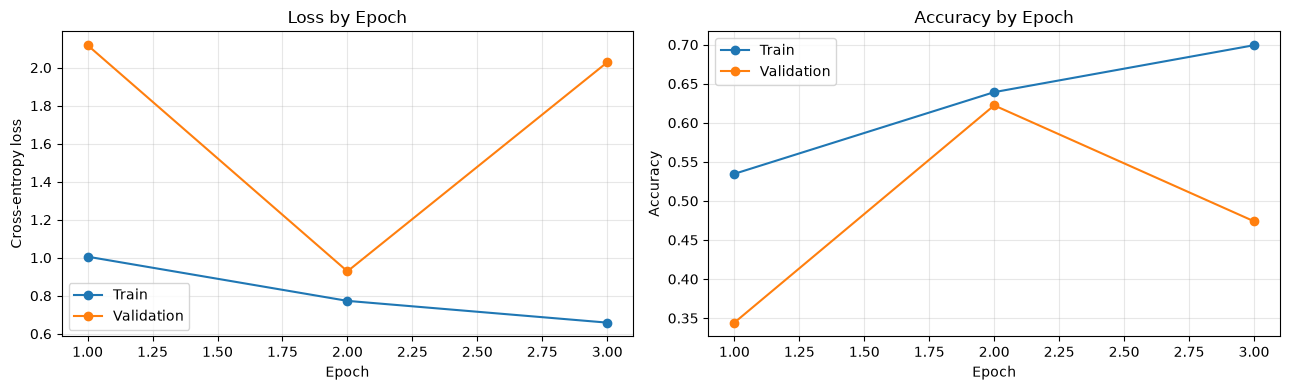

In [8]:
# Reload history from disk so this works after kernel interruption/restart.
history_path = MODEL_OUTPUT_DIR / "training_history.csv"
if not history_path.exists():
    raise FileNotFoundError(f"No training history found at {history_path}. Run training first.")

history_df = pd.read_csv(history_path).sort_values("epoch")
display(history_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train")
axes[0].plot(history_df["epoch"], history_df["validation_loss"], marker="o", label="Validation")
axes[0].set_title("Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_df["epoch"], history_df["train_accuracy"], marker="o", label="Train")
axes[1].plot(history_df["epoch"], history_df["validation_accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Final held-out test evaluation

This cell evaluates the best-validation checkpoint on the test split once. It reports accuracy, precision, recall, F1-score, and a confusion matrix. Because source/patient independence of the saved split has not yet been conclusively established, label these as **provisional test results** until the split-leakage audit is resolved.

PROVISIONAL HELD-OUT TEST RESULTS
Best checkpoint epoch: 2
Best validation loss: 0.9286
Test loss: 0.9155
Test accuracy: 62.1515%
\nPer-class precision, recall and F1:
                  precision    recall  f1-score   support

    MildDemented     0.6899    0.4420    0.5388      1500
ModerateDemented     0.6466    0.9867    0.7812      1500
     NonDemented     0.7959    0.5260    0.6334      1920
VeryMildDemented     0.4560    0.5649    0.5047      1680

        accuracy                         0.6215      6600
       macro avg     0.6471    0.6299    0.6145      6600
    weighted avg     0.6514    0.6215    0.6127      6600



,MildDemented,ModerateDemented,NonDemented,VeryMildDemented
MildDemented,663,394,22,421
ModerateDemented,7,1480,0,13
NonDemented,76,136,1010,698
VeryMildDemented,215,279,237,949


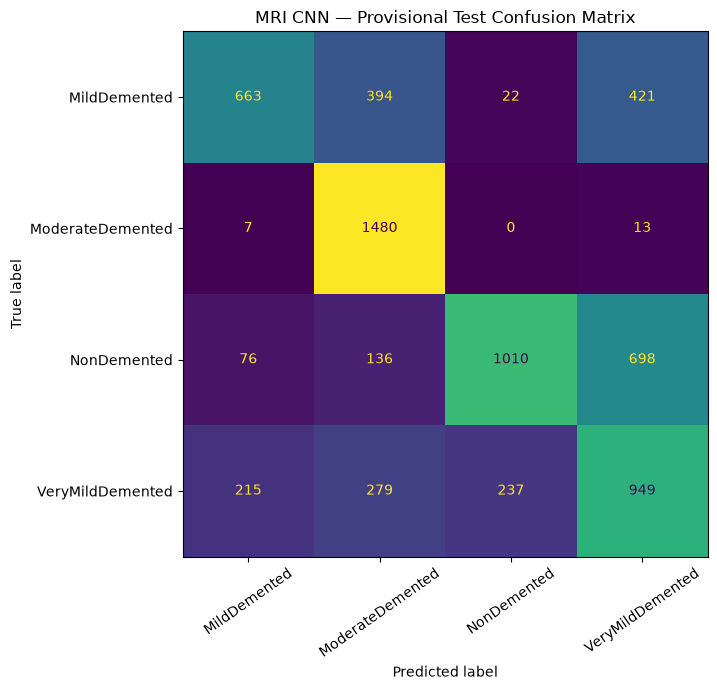

\nSummary saved to: D:\project\Outputs\mri_baseline_cnn\provisional_test_summary.json
These metrics are provisional until source/patient split independence is verified.


In [9]:
# Always evaluate the best saved validation checkpoint, even after a kernel restart.
checkpoint_path = MODEL_OUTPUT_DIR / "alzheimer_cnn_best_validation.pt"
if not checkpoint_path.exists():
    raise FileNotFoundError(f"Best checkpoint not found: {checkpoint_path}. Run training first.")

try:
    saved_checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
except TypeError:
    saved_checkpoint = torch.load(checkpoint_path, map_location=device)

model.load_state_dict(saved_checkpoint["model_state_dict"])
model.eval()
test_metrics = evaluate_model(model, test_loader, criterion, device)
y_true, y_pred = test_metrics["labels"], test_metrics["predictions"]

print("=" * 65)
print("PROVISIONAL HELD-OUT TEST RESULTS")
print("=" * 65)
print(f"Best checkpoint epoch: {saved_checkpoint['best_epoch']}")
print(f"Best validation loss: {saved_checkpoint['best_validation_loss']:.4f}")
print(f"Test loss: {test_metrics['loss']:.4f}")
print(f"Test accuracy: {test_metrics['accuracy']:.4%}")
print("\\nPer-class precision, recall and F1:")
print(classification_report(
    y_true, y_pred, labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES, digits=4, zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
display(pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(8, 7))
disp.plot(ax=ax, xticks_rotation=35, colorbar=False)
ax.set_title("MRI CNN — Provisional Test Confusion Matrix")
plt.tight_layout()
plt.show()

test_summary = {
    "model": "Custom AlzheimerCNN",
    "best_epoch": int(saved_checkpoint["best_epoch"]),
    "test_loss": float(test_metrics["loss"]),
    "test_accuracy": float(test_metrics["accuracy"]),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "dropout_rate": DROPOUT_RATE,
    "train_images": len(train_dataset),
    "validation_images": len(val_dataset),
    "test_images": len(test_dataset),
    "split_independence_verified": False
}
summary_path = MODEL_OUTPUT_DIR / "provisional_test_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(test_summary, f, indent=2)
print("\\nSummary saved to:", summary_path)
print("These metrics are provisional until source/patient split independence is verified.")

## 10. Misclassified test examples

This optional review helps identify which classes the model confuses. It is for error analysis only; do not tune repeatedly against the test set.

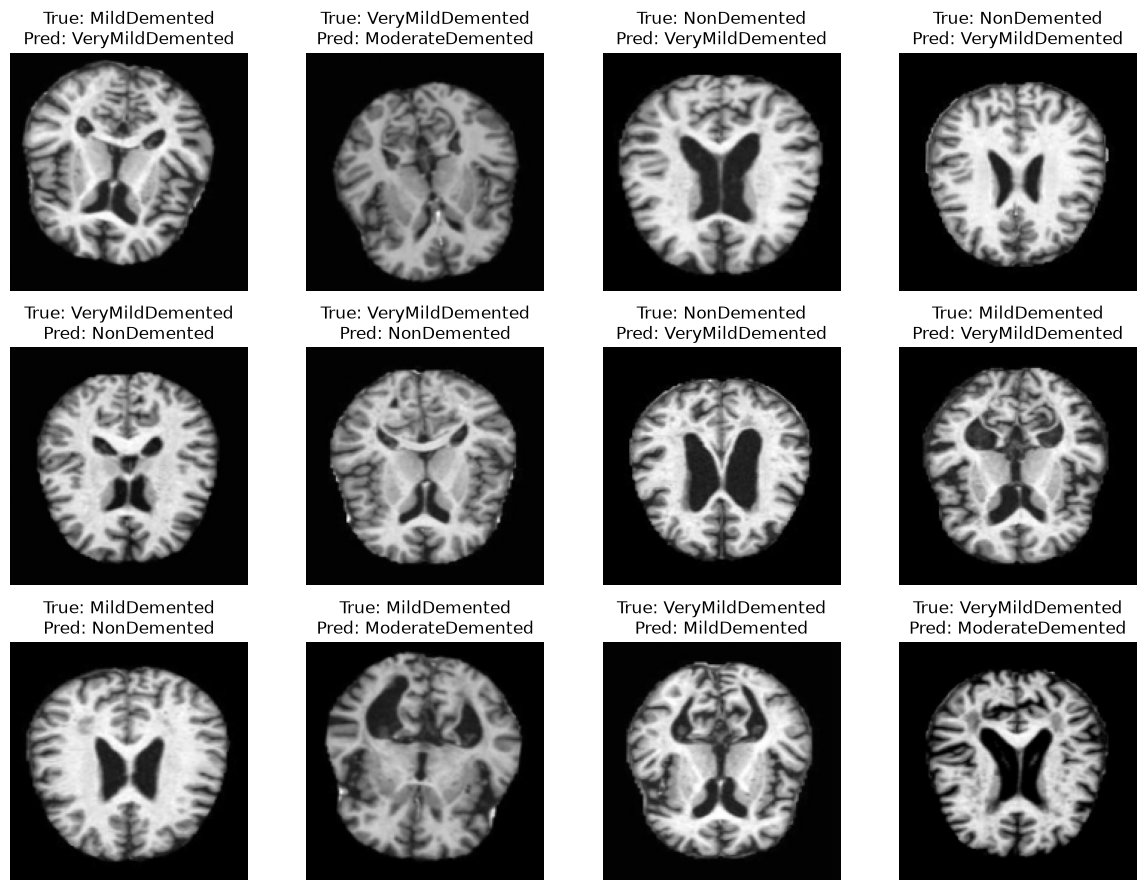

In [10]:
SHOW_MISCLASSIFIED_EXAMPLES = True
MAX_EXAMPLES_TO_SHOW = 12

if SHOW_MISCLASSIFIED_EXAMPLES:
    wrong_indices = np.flatnonzero(y_true != y_pred)[:MAX_EXAMPLES_TO_SHOW]
    if len(wrong_indices) == 0:
        print("No misclassified examples in this test pass.")
    else:
        fig, axes = plt.subplots(
            nrows=int(np.ceil(len(wrong_indices) / 4)),
            ncols=4, figsize=(12, 3 * int(np.ceil(len(wrong_indices) / 4)))
        )
        axes = np.array(axes).reshape(-1)
        for ax, idx in zip(axes, wrong_indices):
            image_tensor, true_label = test_dataset[int(idx)]
            image_show = image_tensor.squeeze(0).numpy()
            image_show = (image_show * 0.5) + 0.5
            ax.imshow(image_show, cmap="gray")
            ax.set_title(
                f"True: {CLASS_NAMES[int(y_true[idx])]}\n"
                f"Pred: {CLASS_NAMES[int(y_pred[idx])]}"
            )
            ax.axis("off")
        for ax in axes[len(wrong_indices):]:
            ax.axis("off")
        plt.tight_layout()
        plt.show()

## 11. Model-comparison section for the next group member

Add other architectures here (for example, a transfer-learning model) and compare them using the **same saved split**, the same preprocessing policy where appropriate, and validation-based model selection. Record model name, parameter count, training time, best validation accuracy/loss, and provisional test metrics. Do not compare models trained on different or accidentally regenerated splits.

Suggested comparison table columns:
- Model / architecture
- Trainable parameters
- Best epoch
- Training time
- Validation accuracy and loss
- Test accuracy, precision, recall, F1-score
- Notes on leakage checks and limitations

### Baseline pilot already completed before this notebook
- Architecture: custom CNN (`AlzheimerCNN`)
- Trainable parameters: **98,148**
- One-epoch training loss: **1.0293**
- One-epoch training accuracy: **52.48%**
- Validation loss: **1.1580**
- Validation accuracy: **50.38%**
- Approximate epoch time on CPU: **22.30 minutes**
- Test accuracy: **not calculated in the earlier pilot**

These figures are historical pilot results from the previous run, not the results of the current notebook until its training cells have been executed.

## 12. Research limitations and next steps

1. **Verify source/patient independence.** The manifest has unique file paths, but that alone does not establish independent samples. Investigate augmentation provenance and duplicate/source groups before making final generalization claims.
2. **Do not treat the filename-normalization audit as conclusive.** Common filenames are reused across class folders, so naive filename grouping can produce false conflicts.
3. **Keep the test set untouched during model selection.** Choose hyperparameters and checkpoints using training/validation data; evaluate the selected model on test data once.
4. **Classify the output carefully.** The current task is four-class MRI image classification, not a confirmed clinical diagnosis. Performance on this dataset alone does not establish clinical readiness.
5. **Multimodal fusion comes later.** This notebook handles the MRI branch only. Combine it with the clinical model only after both branches are separately validated and the patient-level linkage between MRI and clinical records is established.